# 01 EDA
Exploratory analysis of the cleaned Online Retail II transactions and the customer table. Ends with written hypotheses.

In [1]:
import sys
import pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.utils.config import load_config, rpath
cfg = load_config()

In [2]:
tx = pd.read_parquet(rpath(cfg,'interim_transactions'))
print(tx.shape, tx.invoice_date.min(), tx.invoice_date.max())
tx[['quantity','price','line_total']].describe().round(2)

(793850, 10) 2009-12-01 07:45:00 2011-12-09 12:50:00


,quantity,price,line_total
count,793850.00,793850.00,793850.00
mean,11.45,2.97,19.87
std,129.86,4.48,221.47
min,-80995.00,0.03,-168469.60
25%,2.00,1.25,4.35
50%,5.00,1.95,11.70
75%,12.00,3.75,19.50
max,992.00,649.50,38970.00


In [3]:
f = pd.read_parquet(rpath(cfg,'features'))
print('customers', len(f), 'churn rate', round(f.churn.mean(),3), 'zero future spend', round((f.future_spend==0).mean(),3))
f[['recency_days','frequency','monetary_total','avg_basket_size','return_rate']].describe().round(2)

customers 5248 churn rate 0.566 zero future spend 0.567


,recency_days,frequency,monetary_total,avg_basket_size,return_rate
count,5248.00,5248.00,5248.00,5248.00,5248.00
mean,205.86,5.70,2537.47,210.73,0.02
std,173.95,11.18,11882.78,279.69,0.06
min,0.00,1.00,1.55,1.00,0.00
25%,49.00,1.00,316.46,88.00,0.00
50%,163.00,3.00,775.16,149.00,0.00
75%,324.00,6.00,2047.92,253.00,0.02
max,646.00,284.00,452123.53,9783.00,0.76


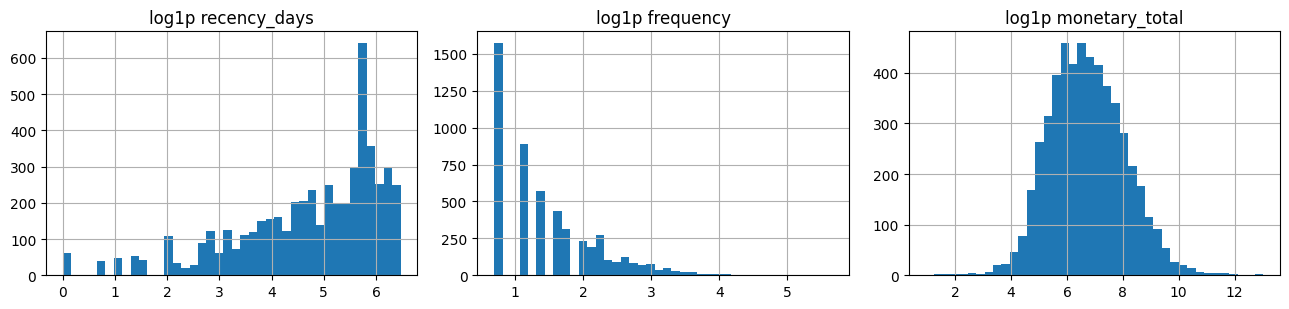

In [4]:
fig, ax = plt.subplots(1,3, figsize=(13,3.2))
for a,c in zip(ax,['recency_days','frequency','monetary_total']):
    np.log1p(f[c]).hist(ax=a, bins=40); a.set_title('log1p '+c)
plt.tight_layout()

In [5]:
f.groupby('country').size().sort_values(ascending=False).head(8)

country
United Kingdom    4791
Germany             92
France              76
Spain               30
Belgium             27
Netherlands         22
Switzerland         20
Sweden              19
dtype: int64

<Axes: title={'center': 'Monthly net revenue (all cleaned lines)'}, xlabel='month'>

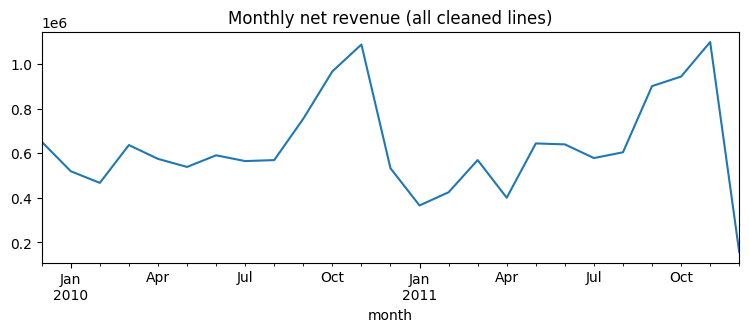

In [6]:
m = tx.assign(month=tx.invoice_date.dt.to_period('M')).groupby('month').line_total.sum()
m.plot(figsize=(9,3), title='Monthly net revenue (all cleaned lines)')

In [7]:
cols=['recency_days','frequency','monetary_total','orders_last_90d','spend_last_90d','return_rate','discount_sensitivity','engagement_score','churn','future_spend']
f[cols].corr().round(2)

,recency_days,frequency,monetary_total,orders_last_90d,spend_last_90d,return_rate,discount_sensitivity,engagement_score,churn,future_spend
recency_days,1.00,-0.30,-0.15,-0.44,-0.19,0.02,-0.03,-0.77,0.43,-0.14
frequency,-0.30,1.00,0.63,0.81,0.56,0.04,0.12,0.52,-0.27,0.49
monetary_total,-0.15,0.63,1.00,0.51,0.88,0.03,0.19,0.27,-0.14,0.84
orders_last_90d,-0.44,0.81,0.51,1.00,0.59,0.00,0.11,0.51,-0.31,0.45
spend_last_90d,-0.19,0.56,0.88,0.59,1.00,0.02,0.17,0.26,-0.15,0.75
return_rate,0.02,0.04,0.03,0.00,0.02,1.00,0.14,0.03,0.01,0.01
discount_sensitivity,-0.03,0.12,0.19,0.11,0.17,0.14,1.00,0.08,0.01,0.14
engagement_score,-0.77,0.52,0.27,0.51,0.26,0.03,0.08,1.00,-0.49,0.21
churn,0.43,-0.27,-0.14,-0.31,-0.15,0.01,0.01,-0.49,1.00,-0.20
future_spend,-0.14,0.49,0.84,0.45,0.75,0.01,0.14,0.21,-0.20,1.00


In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X = f[['recency_days','frequency','monetary_total','avg_basket_size','return_rate','discount_sensitivity','seasonal_concentration','gap_mean_days']].copy()
X = (X-X.mean())/X.std()
pd.Series([variance_inflation_factor(X.values,i) for i in range(X.shape[1])], index=X.columns).round(2).rename('VIF')

recency_days              1.44
frequency                 2.19
monetary_total            1.86
avg_basket_size           1.17
return_rate               1.02
discount_sensitivity      1.13
seasonal_concentration    1.79
gap_mean_days             1.20
Name: VIF, dtype: float64

## Hypotheses the modelling stage tests
1. Recency is the strongest single churn predictor (checked later with SHAP).
2. Customers with high recent order counts churn less, even at equal lifetime spend.
3. Spend is heavy-tailed, so CLV needs a log-scale target and will have low raw R2.
4. Return rate carries signal but is small for most customers.
5. Seasonal (Q4) buyers look like churners outside the holiday window.